<a href="https://colab.research.google.com/github/yoldezboubahri/Analyse-des-reclamations-clients/blob/main/fashion_intelligence_final.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

<div align="center">

# Fashion Intelligence

### Du comportement d'achat à la composition de collection : un pipeline de Machine Learning en trois modèles

**Projet de Machine Learning · E-commerce & Mode**

Réalisé par : **Yoldez Boubahri**

*Données : Amazon Reviews 2023 (McAuley Lab), catégorie Clothing, Shoes & Jewelry*

</div>

## Sommaire

**Partie I : Cadrage**
1. Concept
2. Problématique
3. Objectifs


**Partie II : Données**

4. Configuration
5. Chargement
6. Nettoyage
7. Exploration

**Partie III : Modélisation**

8. Modèle 1 : prédiction des préférences
9. Modèle 2 : prévision des tendances
10. Modèle 3 : composition de la collection

**Partie IV : Synthèse**

11. Conclusion
12. Références

---
# Partie I : Cadrage

## 1. Concept

Chaque saison, une enseigne de mode doit décider **quels articles mettre en avant** dans sa collection. Ce choix repose souvent sur l'intuition des acheteurs ou sur les ventes passées. Or :
- un article qui se vend bien **aujourd'hui** n'est pas forcément celui qui se vendra **demain** ;
- un article populaire n'est pas forcément un article **apprécié** par les clients.

Les **avis clients** contiennent ces deux informations à la fois :
- la **note** (1 à 5) mesure la **satisfaction** ;
- le **nombre d'avis** au cours du temps est un indicateur de la **demande** (un client laisse un avis après un achat).

L'idée du projet est d'exploiter ces deux signaux , pour passer **du comportement d'achat à une proposition de collection**.

| Modèle | Rôle | Sortie transmise |
|---|---|---|
| **Modèle 1 : préférences** | Mesurer la satisfaction | Note attendue de chaque article |
| **Modèle 2 : tendances** | Anticiper la demande | Probabilité qu'un article décolle |
| **Modèle 3 : collection** | Décider | Liste de N articles sous contraintes |

## 2. Problématique

> **Peut-on, à partir des seuls avis clients, identifier à l'avance les articles qui vont gagner en popularité tout en restant appréciés, et en composer une collection plus performante qu'un choix fondé sur des règles simples ?**



## 3. Objectifs

| # | Objectif | Critère de réussite |
|---|---|---|
| O1 | Nettoyer et comprendre les données | Données fiables et exploitables pour la modélisation |
| O2 | Prédire la note qu'un client donnera à un article | Erreur plus faible que la moyenne globale |
| O3 | Prédire quels articles seront en tendance dans les 3 mois | Meilleur classement que le hasard |
| O4 | Composer une collection de 100 articles | les best-sellers, avec une bonne note |
| O5 | Vérifier les prédictions sur une période réelle | Comparaison prédiction / réalité article par article |

---
# Partie II : Données

## 5. Configuration

Tous les paramètres du projet sont regroupés dans une seule cellule : on peut ainsi relancer l'analyse avec d'autres réglages sans chercher dans le code.

In [ ]:
import os, gc, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.sparse import csr_matrix
from scipy.sparse.linalg import svds
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.inspection import permutation_importance
from sklearn.metrics import roc_auc_score, average_precision_score

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.figsize"] = (10, 4.5)
pd.options.display.float_format = "{:,.3f}".format

# Couleurs de la présentation
PRUNE, OR, NUIT, GRIS = "#8E2E51", "#C9A04A", "#441B32", "#A8A0A4"
SEED = 42
rng = np.random.default_rng(SEED)

# Emplacement des données : Google Drive sous Colab, dossier courant sinon
try:
    from google.colab import drive
    drive.mount("/content/drive")
    DOSSIER = "/content/drive/MyDrive"
except ImportError:
    DOSSIER = "."

CHEMIN = os.path.join(DOSSIER, "amazon_reviews.csv.gz")
CHEMIN_META = os.path.join(DOSSIER, "meta_Clothing_Shoes_and_Jewelry.jsonl.gz")  # facultatif

# Modèle 1
N_USERS_M1 = 300_000        # utilisateurs échantillonnés (la SVD sur 2,5 M d'utilisateurs est trop lourde pour Colab)
# Modèle 2
DEBUT_M2 = "2015-01"        # début de la période étudiée
MIN_AVIS_PRODUIT = 20       # on suit les articles ayant au moins 20 avis sur la période
HORIZON = 3                 # nombre de mois à prévoir
COUPURE_M2 = "2022-01"      # entraînement avant cette date, test après
# Modèle 3
TAILLE_COLLECTION = 100
MAX_PAR_MARQUE = 3
NOTE_MIN = 4.0              # note attendue minimale pour entrer dans la collection

Mounted at /content/drive


> **Interprétation**
>
> Les bibliothèques sont chargées et le Drive est monté. Les principaux réglages sont : 300 000 utilisateurs pour le modèle 1, des articles suivis depuis janvier 2015 pour le modèle 2, un horizon de prévision de 3 mois, et une collection de 100 articles.

## 6. Chargement

**Variables disponibles :**

| Variable | Type | Description |
|---|---|---|
| `user_id` | qualitative | identifiant anonyme du client |
| `parent_asin` | qualitative | identifiant de l'article (toutes tailles et couleurs regroupées) |
| `rating` | quantitative ordinale | note de 1 à 5 étoiles |
| `timestamp` | quantitative | date de l'avis, en millisecondes depuis 1970 |

In [ ]:
def lire_avis(chemin):
    try:
        df = pd.read_csv(chemin, engine="pyarrow", dtype_backend="pyarrow")
    except ImportError:          # pyarrow absent : lecture classique
        df = pd.read_csv(chemin)
    df["user_id"] = df["user_id"].astype("category")
    df["parent_asin"] = df["parent_asin"].astype("category")
    df["rating"] = pd.to_numeric(df["rating"], errors="coerce").astype("float32")
    df["timestamp"] = pd.to_numeric(df["timestamp"], errors="coerce").astype("float64")
    return df

brut = lire_avis(CHEMIN)
print(f"{len(brut):,} lignes | mémoire : {brut.memory_usage(deep=True).sum() / 1e9:.2f} Go")
brut.head()

24,257,663 lignes | mémoire : 0.66 Go


,user_id,parent_asin,rating,timestamp
0,AH7X5YKDY4SXKIWGUAKTT36J6J6Q,B0192BU3T0,5.000,"1,607,285,942,725.000"
1,AGEHWSAFMQMDG2OWBE3YZ4QNMWGQ,B07G2KQH3B,5.000,"1,487,007,187,000.000"
2,AGHXRD55KBORVTAQXW7EDQYSPI4Q,B081ZS38MR,5.000,"1,655,766,992,501.000"
3,AEC6ZP5KV5AKQNOF5Z6WOZ2UALUA,B077PZJG7R,NaN,"1,620,070,380,950.000"
4,AGRSY73ZBAFQHU2AXEGXPBXEFFSQ,B07ZJ32GVM,5.000,"1,619,163,000,287.000"


In [ ]:
qualite = pd.DataFrame({
    "manquants (%)": brut.isna().mean() * 100,
    "valeurs uniques": brut.nunique(),
})
qualite

,manquants (%),valeurs uniques
user_id,3.009,2524981
parent_asin,2.998,714957
rating,2.998,11
timestamp,3.002,22276348


> **Interprétation**
>
> - Chaque colonne a **environ 3 % de valeurs manquantes**, une proportion presque identique d'une colonne à l'autre. Cette régularité suggère un bruit ajouté volontairement au jeu de données.
> - `rating` compte **11 valeurs distinctes**, alors qu'une note devrait en avoir 5 : des notes invalides sont présentes.
> - La base couvre **2,5 millions d'utilisateurs** et **715 000 articles**.

## 7. Nettoyage

| Problème | Règle appliquée | Justification |
|---|---|---|
| Doublons exacts | supprimés | un avis compté deux fois surpondère son auteur et son article |
| Notes hors de 1 à 5 (-1, 0, 6, 7, 10, 99) | remplacées par une valeur manquante | la ligne reste un avis valable pour compter les volumes (modèle 2) |
| Utilisateur, article ou date manquant | ligne supprimée | un avis qu'on ne peut ni attribuer ni dater est inutilisable |

> **Pourquoi ce choix ?**
>
> On évite de supprimer toutes les lignes incomplètes d'un coup (`dropna()` global). Une ligne sans note mais avec un article et une date reste utile : elle compte comme un achat dans le modèle 2. Chaque modèle filtre seulement les colonnes dont il a besoin.

In [ ]:
n0 = len(brut)
df = brut.drop_duplicates().reset_index(drop=True)
del brut; gc.collect()
n_doublons = n0 - len(df)

invalide = df["rating"].notna() & ~df["rating"].isin([1, 2, 3, 4, 5])
n_invalides = int(invalide.sum())
df.loc[invalide, "rating"] = np.nan

n_avant = len(df)
df = df.dropna(subset=["user_id", "parent_asin", "timestamp"]).reset_index(drop=True)
n_incomplets = n_avant - len(df)

df["date"] = pd.to_datetime(df["timestamp"], unit="ms")
df["mois_num"] = (df["date"].dt.year * 12 + df["date"].dt.month - 1).astype("int32")  # mois numéroté
df = df.drop(columns="timestamp")
for col in ["user_id", "parent_asin"]:
    df[col] = df[col].cat.remove_unused_categories()

def vers_mois(n):
    """Numéro de mois -> période (ex. 24277 -> 2023-02)."""
    return pd.Period(year=int(n) // 12, month=int(n) % 12 + 1, freq="M")

bilan = pd.Series({
    "Lignes brutes": n0,
    "Doublons supprimés": n_doublons,
    "Notes invalides -> manquantes": n_invalides,
    "Lignes incomplètes supprimées": n_incomplets,
    "Lignes conservées": len(df),
    "Dont avec une note valide": int(df["rating"].notna().sum()),
})
bilan.to_frame("nombre").style.format("{:,.0f}")

,nombre
Lignes brutes,"24,257,663"
Doublons supprimés,"1,157,133"
Notes invalides -> manquantes,"461,558"
Lignes incomplètes supprimées,"2,017,965"
Lignes conservées,"21,082,565"
Dont avec une note valide,"20,029,866"


> **Interprétation**
>
> - Environ **1,16 million de doublons** (4,8 % des lignes) sont supprimés.
> - Environ **460 000 notes invalides** (2 %) deviennent des valeurs manquantes, sans perdre la ligne.
> - Les lignes sans utilisateur, sans article ou sans date sont retirées, soit environ 9 % (une valeur manquante sur l'une des trois colonnes).
>
> On obtient une table propre, avec une date et un numéro de mois pour chaque avis.

## 8. Exploration

L'exploration répond à quatre questions, chacune utile pour un modèle :

| Question | Utilité |
|---|---|
| Comment les notes sont-elles réparties ? | choix des métriques du modèle 1 |
| Combien d'avis par utilisateur et par article ? | choix de la méthode du modèle 1 |
| Comment le volume évolue-t-il dans le temps ? | découpage temporel, limite de fin de données |
| Y a-t-il une saisonnalité ? | variables du modèle 2 |

### 8.1 Répartition des notes

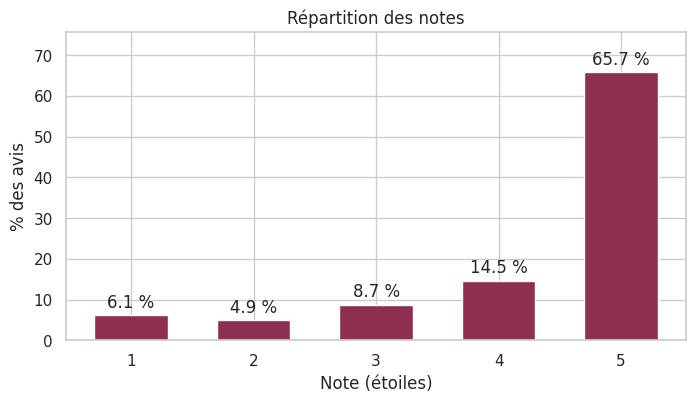

Note moyenne : 4.29 | médiane : 5
Avis positifs (≥ 4) : 80.3% | négatifs (≤ 2) : 11.1%


In [ ]:
notes = df["rating"].dropna()
part = notes.value_counts(normalize=True).sort_index() * 100

fig, ax = plt.subplots(figsize=(8, 4))
barres = ax.bar(part.index.astype(int).astype(str), part.values, color=PRUNE, width=0.6)
ax.bar_label(barres, fmt="%.1f %%", padding=3)
ax.set_title("Répartition des notes")
ax.set_xlabel("Note (étoiles)")
ax.set_ylabel("% des avis")
ax.set_ylim(0, part.max() * 1.15)
plt.show()

print(f"Note moyenne : {notes.mean():.2f} | médiane : {notes.median():.0f}")
print(f"Avis positifs (≥ 4) : {(notes >= 4).mean():.1%} | négatifs (≤ 2) : {(notes <= 2).mean():.1%}")

> **Interprétation**
>
> - **65,7 % des avis sont des 5 étoiles** et **80 % sont positifs** (≥ 4). La note moyenne est de **4,29**.
> - Les clients notent donc très généreusement.
>
> **Conséquence :** il faut comparer chaque modèle à cette moyenne (baseline), et ajouter une métrique de **classement** (AUC) qui mesure si le modèle distingue les avis positifs des avis négatifs.

### 8.2 Activité des utilisateurs et des articles

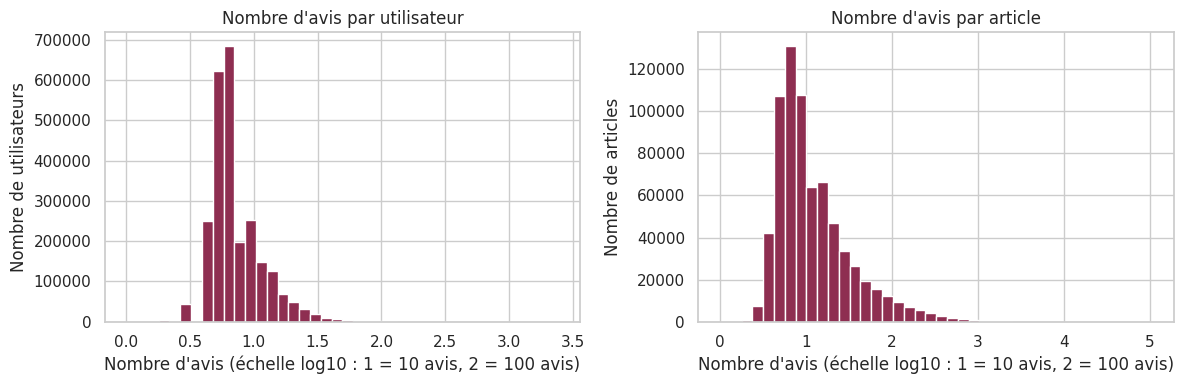

Utilisateurs : 2,524,977 | articles : 714,955
Avis par utilisateur : médiane 6 | avis par article : médiane 9
Sparsité de la matrice utilisateur x article : 99.99883%


In [ ]:
avis_user = df.groupby("user_id", observed=True).size()
avis_article = df.groupby("parent_asin", observed=True).size()
sparsite = 1 - len(df) / (len(avis_user) * len(avis_article))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, s, titre in [(axes[0], avis_user, "utilisateur"), (axes[1], avis_article, "article")]:
    ax.hist(np.log10(s), bins=40, color=PRUNE)
    ax.set_title(f"Nombre d'avis par {titre}")
    ax.set_xlabel("Nombre d'avis (échelle log10 : 1 = 10 avis, 2 = 100 avis)")
    ax.set_ylabel(f"Nombre de {titre}s")
plt.tight_layout()
plt.show()

print(f"Utilisateurs : {len(avis_user):,} | articles : {len(avis_article):,}")
print(f"Avis par utilisateur : médiane {avis_user.median():.0f} | avis par article : médiane {avis_article.median():.0f}")
print(f"Sparsité de la matrice utilisateur x article : {sparsite:.5%}")

> **Interprétation**
>
> - La **médiane est de 6 avis par utilisateur** et de **9 avis par article**. Presque tous ont au moins 5 avis.
> - La matrice utilisateurs × articles est vide à **99,999 %** : chaque client n'a noté qu'une poignée d'articles parmi 715 000.
>
> **Conséquence :** on ne peut pas modéliser chaque paire client-article séparément. On utilise le **filtrage collaboratif**, qui apprend des profils communs à partir des clients qui se ressemblent.

### 8.3 Évolution dans le temps

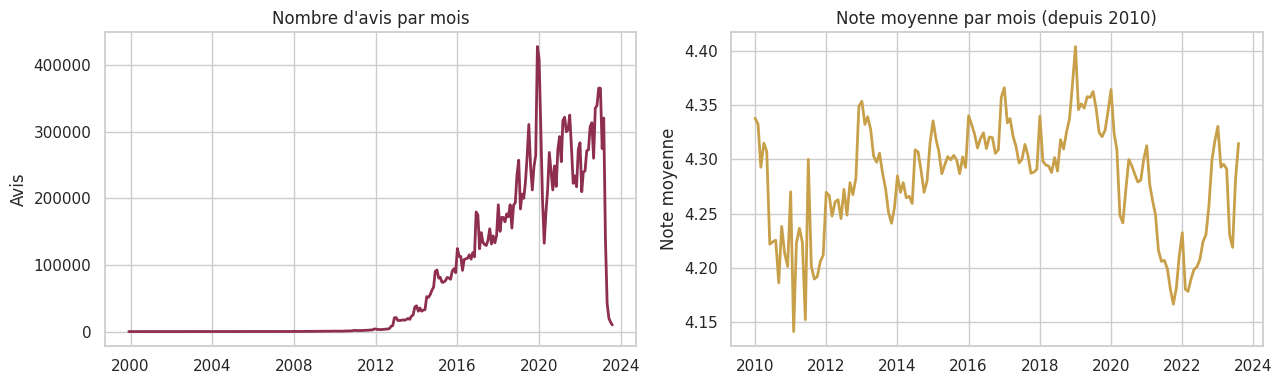

Période : 1999-12-01 -> 2023-09-12


In [ ]:
par_mois = df.groupby(df["date"].dt.to_period("M")).agg(avis=("rating", "size"), note=("rating", "mean"))
par_mois.index = par_mois.index.to_timestamp()
par_mois = par_mois.iloc[:-1]   # le dernier mois est incomplet

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].plot(par_mois.index, par_mois["avis"], color=PRUNE, lw=2)
axes[0].set_title("Nombre d'avis par mois")
axes[0].set_ylabel("Avis")
recent = par_mois[par_mois.index >= "2010-01-01"]
axes[1].plot(recent.index, recent["note"], color=OR, lw=2)
axes[1].set_title("Note moyenne par mois (depuis 2010)")
axes[1].set_ylabel("Note moyenne")
plt.tight_layout()
plt.show()

print("Période :", df["date"].min().date(), "->", df["date"].max().date())

> **Interprétation**
>
> - **Volume :** quasi nul avant 2012, il croît fortement ensuite, atteint un pic en 2020 (plus de 400 000 avis par mois, effet probable du confinement et de l'achat en ligne), puis **s'effondre à la fin de 2023**. Cet effondrement ne reflète pas une baisse des ventes : les données ont été collectées en 2023, et les avis les plus récents sont incomplets.
> - **Note moyenne :** elle reste stable entre 4,15 et 4,40 sur toute la période.


### 8.4 Saisonnalité

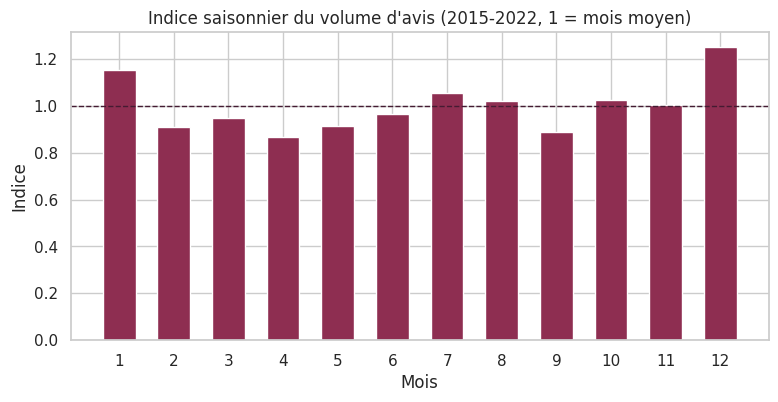

In [ ]:
annees_completes = df[(df["date"].dt.year >= 2015) & (df["date"].dt.year <= 2022)]
saison = annees_completes.groupby([annees_completes["date"].dt.year, annees_completes["date"].dt.month]).size()
saison = saison / saison.groupby(level=0).transform("mean")   # 1 = mois moyen de l'année
indice = saison.groupby(level=1).mean()

fig, ax = plt.subplots(figsize=(9, 4))
ax.bar(indice.index.astype(str), indice.values, color=PRUNE, width=0.6)
ax.axhline(1, color=NUIT, lw=1, ls="--")
ax.set_title("Indice saisonnier du volume d'avis (2015-2022, 1 = mois moyen)")
ax.set_xlabel("Mois")
ax.set_ylabel("Indice")
plt.show()

> **Interprétation**
>
> - **Décembre** (1,25) et **janvier** (1,15) sont les mois les plus actifs : achats de fin d'année, puis avis laissés après réception des cadeaux.
> - **Juillet** est légèrement au-dessus de la moyenne (soldes d'été), alors que **avril** et **septembre** sont les mois les plus calmes.
>
> **Conséquence :** le mois de la période prévue sera une variable du modèle 2. La cible « tendance » sera aussi définie **par rapport au marché**, pour ne pas confondre un pic saisonnier général avec la tendance d'un article.

---
# Partie III : Modélisation

## 9. Modèle 1 : prédiction des préférences

**Question :** quelle note un client donnera-t-il à un article ?
**Cible :** `rating`, de 1 à 5.

### Pourquoi cette méthode ?

| Modèle | Formule | Rôle |
|---|---|---|
| Moyenne globale | note = μ | **référence** : ce qu'on obtient sans rien apprendre |
| Biais | note = μ + b_client + b_article | capte les clients sévères ou généreux, et les articles bons ou mauvais |
| Biais + SVD | … + p_client · q_article | ajoute des **goûts latents** (par exemple, l'affinité d'un client pour un style) |

- **Les biais** sont la base de tous les systèmes de recommandation . Ils sont **régularisés** par un paramètre λ : un article noté seulement 2 fois ne doit pas recevoir un biais extrême.
- **La SVD** (factorisation matricielle). Elle est adaptée aux matrices très creuses comme la nôtre.
- On commence par le plus simple, et on ne garde la SVD que si elle améliore réellement les résultats.

### Découpage

Pour chaque client, les avis sont triés par date : le **dernier** sert au test, l'**avant-dernier** à la validation, et tous les **autres** à l'entraînement.

In [ ]:
avec_note = df.dropna(subset=["rating"])[["user_id", "parent_asin", "rating", "date"]]
nb_notes = avec_note.groupby("user_id", observed=True).size()
eligibles = nb_notes[nb_notes >= 3].index.to_numpy()
echantillon = rng.choice(eligibles, size=min(N_USERS_M1, len(eligibles)), replace=False)

m1 = avec_note[avec_note["user_id"].isin(echantillon)].copy()
del avec_note; gc.collect()
for col in ["user_id", "parent_asin"]:
    m1[col] = m1[col].cat.remove_unused_categories()
m1["u"] = m1["user_id"].cat.codes.astype("int32")      # identifiants -> entiers 0..n-1
m1["i"] = m1["parent_asin"].cat.codes.astype("int32")
NU, NI = len(m1["user_id"].cat.categories), len(m1["parent_asin"].cat.categories)

m1 = m1.sort_values(["u", "date"])
m1["rang"] = m1.groupby("u").cumcount(ascending=False)   # 0 = avis le plus récent
train, valid, test = m1[m1["rang"] >= 2], m1[m1["rang"] == 1], m1[m1["rang"] == 0]

print(f"Utilisateurs : {NU:,} | articles : {NI:,}")
print(f"Entraînement : {len(train):,} | validation : {len(valid):,} | test : {len(test):,}")

Utilisateurs : 300,000 | articles : 495,616
Entraînement : 1,792,282 | validation : 300,000 | test : 300,000


> **Interprétation**
>
> - On a tiré **300 000 clients** au hasard parmi ceux qui ont au moins 3 notes
> - Cela représente **495 616 articles** et environ **2,4 millions de notes**.
> - Les ensembles de validation et de test contiennent chacun **300 000 avis**, un par client.

Le modèle tient en deux fonctions : `entrainer` (calcul de μ, des biais et de la SVD) et `predire`. Un article jamais vu à l'entraînement reçoit un biais et des facteurs nuls : sa prédiction retombe sur μ + b_client.

# Système de recommandation : biais + facteurs latents (SVD)

## 1. Modèle de prédiction

$$\hat r_{ui} = \mu + b_u + b_i + p_u \cdot q_i$$

- **μ** : note moyenne globale
- **b_i** : biais de l'item (qualité propre de l'item)
- **b_u** : biais de l'utilisateur (tendance à noter haut ou bas)
- **p_u · q_i** : interaction latente utilisateur–item (goûts spécifiques)

## 2. Biais régularisés

$$b_i = \frac{\sum_{u \in R_i} (r_{ui} - \mu)}{|R_i| + \lambda}$$

$$b_u = \frac{\sum_{i \in R_u} (r_{ui} - \mu - b_i)}{|R_u| + \lambda}$$

Moyenne des écarts, ramène vers 0 les biais estimés sur peu de notes. Les biais items sont calculés d'abord, puis les biais utilisateurs sur les résidus restants.

## 3. Facteurs latents (SVD tronquée)

$$R_{res} = r_{ui} - \mu - b_i - b_u \approx U_k \Sigma_k V_k^T = P\,Q^T$$

$$P = U_k \Sigma_k, \qquad Q = V_k$$

On factorise la matrice des résidus en gardant les **k** plus grandes valeurs singulières. Les cases non notées valent 0.

## 4. Métriques d'évaluation

$$\text{RMSE} = \sqrt{\frac{1}{n}\sum_{j}(y_j-\hat y_j)^2}$$

$$\text{MAE} = \frac{1}{n}\sum_{j}|y_j-\hat y_j|$$

- **RMSE** : pénalise fortement les grosses erreurs.
- **MAE** : erreur absolue moyenne, plus robuste aux outliers.
- **AUC (avis ≥ 4)** : probabilité qu'un avis positif (note ≥ 4) reçoive un score supérieur à celui d'un avis non positif (0,5 = hasard, 1 = parfait).

## 5. Hyperparamètres

| Paramètre | Effet |
|---|---|
| `lam` ↑ | biais plus rétractés vers 0 (moins de surapprentissage, risque de sous-apprentissage) |
| `k` ↑ | modèle plus expressif, risque de surapprentissage ; `k=0` = biais seuls |

In [ ]:
def entrainer(data, k=20, lam=10.0):
    """k = nombre de facteurs latents (0 = biais seuls), lam = régularisation des biais."""
    u, i = data["u"].to_numpy(), data["i"].to_numpy()
    mu = float(data["rating"].mean())
    r = data["rating"].to_numpy(dtype="float64") - mu
    bi = np.bincount(i, weights=r, minlength=NI) / (np.bincount(i, minlength=NI) + lam)
    r = r - bi[i]
    bu = np.bincount(u, weights=r, minlength=NU) / (np.bincount(u, minlength=NU) + lam)
    r = r - bu[u]
    modele = {"mu": mu, "bu": bu, "bi": bi, "P": None, "Q": None}
    if k > 0:
        residus = csr_matrix((r, (u, i)), shape=(NU, NI))
        U, s, Vt = svds(residus, k=k, random_state=SEED)
        modele["P"], modele["Q"] = U * s, Vt.T
    return modele

def predire(modele, u, i, latent=True):
    pred = modele["mu"] + modele["bu"][u] + modele["bi"][i]
    if latent and modele["P"] is not None:
        pred = pred + np.einsum("ij,ij->i", modele["P"][u], modele["Q"][i])
    return np.clip(pred, 1, 5)

def scores(y, pred):
    return {
        "RMSE": np.sqrt(np.mean((y - pred) ** 2)),
        "MAE": np.mean(np.abs(y - pred)),
        "AUC (avis ≥ 4)": roc_auc_score(y >= 4, pred) if np.ptp(pred) > 0 else 0.5,
    }

### 9.1 Choix des réglages sur la validation

On fait varier λ (force de la régularisation) puis k (nombre de facteurs latents), et on garde les valeurs qui minimisent l'erreur sur la **validation**. Le test n'est utilisé qu'une seule fois, à la fin, pour une évaluation honnête.

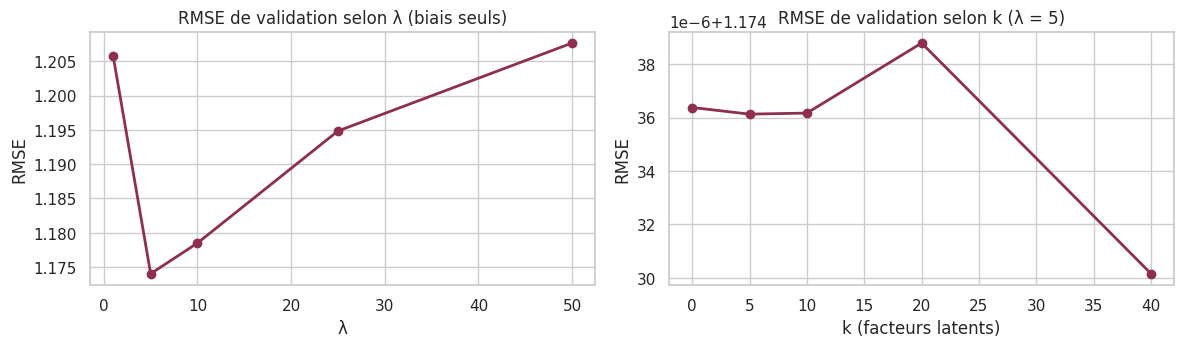

Réglages retenus : λ = 5, k = 40


In [ ]:
yv = valid["rating"].to_numpy()
uv, iv = valid["u"].to_numpy(), valid["i"].to_numpy()

res_lam = {lam: scores(yv, predire(entrainer(train, k=0, lam=lam), uv, iv))["RMSE"] for lam in [1, 5, 10, 25, 50]}
meilleur_lam = min(res_lam, key=res_lam.get)

res_k = {}
for k in [0, 5, 10, 20, 40]:
    res_k[k] = scores(yv, predire(entrainer(train, k=k, lam=meilleur_lam), uv, iv))["RMSE"]
meilleur_k = min(res_k, key=res_k.get)

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
axes[0].plot(list(res_lam), list(res_lam.values()), marker="o", color=PRUNE, lw=2)
axes[0].set(title="RMSE de validation selon λ (biais seuls)", xlabel="λ", ylabel="RMSE")
axes[1].plot(list(res_k), list(res_k.values()), marker="o", color=PRUNE, lw=2)
axes[1].set(title=f"RMSE de validation selon k (λ = {meilleur_lam})", xlabel="k (facteurs latents)", ylabel="RMSE")
plt.tight_layout()
plt.show()
print(f"Réglages retenus : λ = {meilleur_lam}, k = {meilleur_k}")

> **Interprétation**
>
> - **λ = 5** donne la plus petite erreur. Sans régularisation (λ = 1), les articles rares reçoivent des biais extrêmes, et l'erreur remonte. À l'inverse, une régularisation trop forte (λ = 50) écrase toute l'information.
> - **k = 40** est retenu, mais l'échelle du graphique de droite est de l'ordre de **0,000001** : la SVD ne change pratiquement rien à l'erreur. Les goûts latents n'apportent presque rien de plus que les biais sur ces données.

### 9.2 Évaluation finale sur le test

In [ ]:
train_complet = pd.concat([train, valid])
modele_biais = entrainer(train_complet, k=0, lam=meilleur_lam)
modele_svd = entrainer(train_complet, k=max(meilleur_k, 5), lam=meilleur_lam)

yt, ut, it = test["rating"].to_numpy(), test["u"].to_numpy(), test["i"].to_numpy()
resultats_m1 = pd.DataFrame({
    "Moyenne globale": scores(yt, np.full(len(yt), modele_biais["mu"])),
    "Biais utilisateur + article": scores(yt, predire(modele_biais, ut, it)),
    f"Biais + SVD (k = {max(meilleur_k, 5)})": scores(yt, predire(modele_svd, ut, it)),
}).T
resultats_m1

,RMSE,MAE,AUC (avis ≥ 4)
Moyenne globale,1.303,1.014,0.500
Biais utilisateur + article,1.231,0.908,0.693
Biais + SVD (k = 40),1.231,0.908,0.693


> **Interprétation**
>
> | Modèle | RMSE | MAE | AUC |
> |---|---|---|---|
> | Moyenne globale | 1,303 | 1,014 | 0,500 |
> | Biais | **1,231** | **0,908** | **0,693** |
> | Biais + SVD | 1,231 | 0,908 | 0,693 |
>
> - **RMSE et MAE** mesurent l'écart moyen entre la note prédite et la note réelle (plus bas = mieux). Les biais réduisent l'erreur de **10 % (MAE)** par rapport à la moyenne.
> - **L'AUC de 0,69** signifie que, si l'on prend au hasard un avis positif et un avis négatif, le modèle donne la note la plus haute à l'avis positif dans 69 % des cas (contre 50 % au hasard).
> - **La SVD n'apporte rien** : avec des notes aussi concentrées sur 5 étoiles et des clients qui ont peu noté, l'essentiel de l'information est déjà porté par les biais. **Le modèle le plus simple suffit.**

## 9.3 Métriques de ranking : HitRate@10 et NDCG@10

Pour chaque utilisateur, on classe les items candidats par score prédit et on regarde où se trouve **l'item de test** (celui que l'utilisateur a réellement aimé).

### HitRate@10 : l'item est-il dans le top 10 ?

- Pour chaque utilisateur : **1** si l'item de test est dans le top 10, **0** sinon.
- Le HitRate est la moyenne sur tous les utilisateurs.
- Exemple : HitRate@10 = 0,619 signifie que pour 61,9 % des utilisateurs, l'item de test est dans le top 10.


### NDCG@10 : l'item est-il bien placé ?

- Même principe, mais plus l'item est haut dans la liste, plus il rapporte de points.
- Avec un seul item de test par utilisateur : $\text{NDCG@10} = \dfrac{1}{\log_2(\text{rang}+1)}$ si rang ≤ 10, sinon 0.

| Rang de l'item | 1 | 2 | 3 | 5 | 10 | > 10 |
|---|---|---|---|---|---|---|
| Points | 1,00 | 0,63 | 0,50 | 0,39 | 0,29 | 0 |

### Comment les lire ensemble

- **NDCG ≤ HitRate** toujours.
- Plus l'écart est grand, plus les items trouvés sont placés **bas** dans le top 10.

**Pourquoi ces métriques ?** RMSE et MAE mesurent la qualité de la note prédite. HitRate et NDCG mesurent la qualité du **classement**, ce qui compte vraiment pour un système de recommandation.

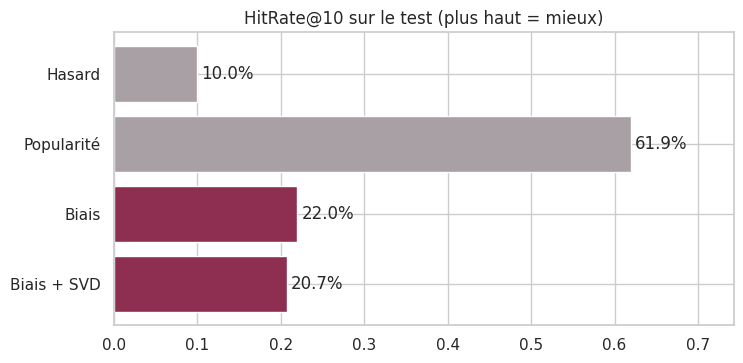

,HitRate@10,NDCG@10
Hasard,0.100,NaN
Popularité,0.619,0.404
Biais,0.220,0.123
Biais + SVD,0.207,0.117


In [ ]:
def hitrate_ndcg(fonction_score, n_users=10_000, n_neg=99):
    connus = np.flatnonzero(np.bincount(train_complet["i"], minlength=NI) > 0)
    cas = test[np.isin(test["i"], connus)].sample(min(n_users, len(test)), random_state=SEED)
    u = cas["u"].to_numpy()
    candidats = np.column_stack([cas["i"].to_numpy(), rng.choice(connus, size=(len(cas), n_neg))])
    s = fonction_score(np.repeat(u, n_neg + 1), candidats.ravel()).reshape(candidats.shape)
    rang = (s[:, 1:] > s[:, [0]]).sum(axis=1)       # 0 = le vrai article est classé 1er
    dans_top = rang < 10
    return {"HitRate@10": dans_top.mean(), "NDCG@10": np.where(dans_top, 1 / np.log2(rang + 2), 0).mean()}

popularite = np.bincount(train_complet["i"], minlength=NI).astype(float)
classement_m1 = pd.DataFrame({
    "Hasard": {"HitRate@10": 0.10, "NDCG@10": np.nan},
    "Popularité": hitrate_ndcg(lambda u, i: popularite[i] + rng.random(len(i)) * 1e-6),
    "Biais": hitrate_ndcg(lambda u, i: predire(modele_biais, u, i)),
    "Biais + SVD": hitrate_ndcg(lambda u, i: predire(modele_svd, u, i)),
}).T

fig, ax = plt.subplots(figsize=(8, 3.8))
barres = ax.barh(classement_m1.index, classement_m1["HitRate@10"], color=[GRIS, GRIS, PRUNE, PRUNE])
ax.bar_label(barres, padding=3, labels=[f"{v:.1%}" for v in classement_m1["HitRate@10"]])
ax.set_title("HitRate@10 sur le test (plus haut = mieux)")
ax.set_xlim(0, classement_m1["HitRate@10"].max() * 1.2)
ax.invert_yaxis()
plt.show()
classement_m1

> **Interprétation**
>
> - **La popularité gagne nettement : 61,9 %**, contre 22 % pour les biais et 10 % pour le hasard.
> - Ce n'est pas un échec du modèle 1. Il répond à une autre question : prédire **la note qu'un client donnera** et prédire **ce qu'il va choisir** sont deux problèmes différents. Un article excellent mais peu connu sera bien noté, mais rarement acheté.


### Conclusion du modèle 1

- Le **modèle à biais** est retenu : il est simple, interprétable et aussi performant que la SVD.


## 10. Modèle 2 : prévision des tendances

**Question :** quels articles vont devenir plus populaires dans les 3 prochains mois ?

**Définition :** un article est **en tendance** si, sur les 3 mois suivants :
- il reçoit **beaucoup plus d'avis que d'habitude**, soit au moins **1,5 fois** la croissance moyenne du marché ;
- et il reçoit **au moins 5 avis**.

### Pourquoi cette définition ?

- **On compare au marché :** si tous les articles montent en décembre, ça ne compte pas. Un article est en tendance seulement s'il progresse **plus vite que les autres**.
- **Minimum de 5 avis :** passer de 0 à 1 avis n'est pas une vraie tendance.
- **Les avis remplacent les ventes :** on n'a pas les ventes réelles, donc le nombre d'avis sert d'indicateur de popularité.


### 10.1 Séries mensuelles par article

In [ ]:
debut_num = pd.Period(DEBUT_M2, "M").year * 12 + pd.Period(DEBUT_M2, "M").month - 1
fin_num = int(df["mois_num"].max()) - 1          # le dernier mois est incomplet
fen = df[(df["mois_num"] >= debut_num) & (df["mois_num"] <= fin_num)]

compte = fen.groupby("parent_asin", observed=True).size()
produits = pd.Index(compte[compte >= MIN_AVIS_PRODUIT].index.astype(str))
fen = fen[fen["parent_asin"].astype(str).isin(produits)]
p = produits.get_indexer(fen["parent_asin"].astype(str)).astype(np.int64)   # article -> ligne du tableau
t = (fen["mois_num"].to_numpy() - debut_num).astype(np.int64)
NP, NT = len(produits), fin_num - debut_num + 1

def matrice(poids=None):
    """Tableau articles x mois, puis cumul dans le temps (pour sommer une fenêtre en une soustraction)."""
    m = np.bincount(p * NT + t, weights=poids, minlength=NP * NT).reshape(NP, NT)
    return np.hstack([np.zeros((NP, 1)), m.cumsum(axis=1)])

a_note = fen["rating"].notna().to_numpy()
CUM_AVIS = matrice()
CUM_SOMME_NOTES = matrice(np.where(a_note, fen["rating"].fillna(0).to_numpy(), 0))
CUM_NB_NOTES = matrice(a_note.astype(float))
premier_mois = df.groupby("parent_asin", observed=True)["mois_num"].min()
premier_mois = premier_mois.set_axis(premier_mois.index.astype(str)).reindex(produits).to_numpy()
del fen, p, t, a_note; gc.collect()

def fenetre(cumul, a, b):
    """Somme des mois a à b inclus (indices de colonnes) pour tous les articles."""
    a, b = max(a, 0), min(b, NT - 1)
    return cumul[:, b + 1] - cumul[:, a]

print(f"Articles suivis : {NP:,} | mois : {NT} ({vers_mois(debut_num)} -> {vers_mois(fin_num)})")

Articles suivis : 169,689 | mois : 104 (2015-01 -> 2023-08)


> **Interprétation**
>
> On suit **169 689 articles** (ceux qui ont au moins 20 avis depuis 2015) sur **104 mois**, de janvier 2015 à août 2023. Chaque article devient une série mensuelle du nombre d'avis. Le mois de septembre 2023, incomplet, est écarté.

### 10.2 Construction du jeu de données

**Variables explicatives**, calculées uniquement avec le passé :

| Variable | Signification |
|---|---|
| `log_avis_1m`, `log_avis_3m`, `log_avis_12m` | volume récent (en log, car quelques articles concentrent l'essentiel des avis) |
| `croissance_3m` | les 3 derniers mois comparés aux 3 mois précédents |
| `part_marche_3m` | poids de l'article dans le marché |
| `age_mois` | ancienneté de l'article |
| `note_6m` | note moyenne des 6 derniers mois |
| `mois_sin`, `mois_cos` | mois de la période prévue, codé sur un cercle pour que décembre soit proche de janvier |

**Découpage :** on se place tous les 3 mois à une date donnée. Les dates dont l'horizon se termine avant janvier 2022 servent à l'**entraînement**, celles d'après au **test**.

In [ ]:
VARIABLES = ["log_avis_1m", "log_avis_3m", "log_avis_12m", "croissance_3m",
             "part_marche_3m", "age_mois", "note_6m", "mois_sin", "mois_cos"]

def construire(t):
    """Une ligne par article actif au mois t : variables (passé) et cible (3 mois suivants)."""
    v1, v3 = fenetre(CUM_AVIS, t, t), fenetre(CUM_AVIS, t - 2, t)
    v3_avant, v12 = fenetre(CUM_AVIS, t - 5, t - 3), fenetre(CUM_AVIS, t - 11, t)
    nb6 = fenetre(CUM_NB_NOTES, t - 5, t)
    note6 = np.divide(fenetre(CUM_SOMME_NOTES, t - 5, t), nb6, out=np.full(NP, np.nan), where=nb6 > 0)
    mois_prevu = (debut_num + t + 1) % 12 + 1
    X = pd.DataFrame({
        "produit": np.arange(NP), "t": t,
        "log_avis_1m": np.log1p(v1), "log_avis_3m": np.log1p(v3), "log_avis_12m": np.log1p(v12),
        "croissance_3m": np.log((v3 + 1) / (v3_avant + 1)),
        "part_marche_3m": np.log1p(1e5 * v3 / max(v3.sum(), 1)),
        "age_mois": debut_num + t - premier_mois,
        "note_6m": note6,
        "mois_sin": np.sin(2 * np.pi * mois_prevu / 12), "mois_cos": np.cos(2 * np.pi * mois_prevu / 12),
        "avis_3m": v3,
    })
    if t + HORIZON <= NT - 1:                     # le futur est connu : on calcule la cible
        f3 = fenetre(CUM_AVIS, t + 1, t + HORIZON)
        croissance_marche = f3.sum() / max(v3.sum(), 1)
        X["avis_futurs"] = f3
        nbf = fenetre(CUM_NB_NOTES, t + 1, t + HORIZON)
        X["note_future"] = np.divide(fenetre(CUM_SOMME_NOTES, t + 1, t + HORIZON), nbf,
                                     out=np.full(NP, np.nan), where=nbf > 0)
        X["tendance"] = (((f3 + 1) / (v3 + 1) >= 1.5 * croissance_marche) & (f3 >= 5)).astype(int)
    actif = (X["age_mois"] >= 6) & (v12 >= 3)     # l'article existe depuis 6 mois et vit encore
    return X[actif].reset_index(drop=True)

coupure = pd.Period(COUPURE_M2, "M")
t_coupure = coupure.year * 12 + coupure.month - 1 - debut_num
dates_train = [t for t in range(11, NT - HORIZON, 3) if t + HORIZON < t_coupure]
dates_test = [t for t in range(11, NT - HORIZON, 3) if t >= t_coupure]

d_train = pd.concat([construire(t) for t in dates_train], ignore_index=True)
d_test = pd.concat([construire(t) for t in dates_test], ignore_index=True)
if len(d_train) > 1_500_000:
    d_train = d_train.sample(1_500_000, random_state=SEED)
note_moy_train = d_train["note_6m"].mean()
for d in (d_train, d_test):
    d["note_6m"] = d["note_6m"].fillna(note_moy_train)

print(f"Entraînement : {len(d_train):,} lignes ({len(dates_train)} dates, {vers_mois(debut_num + dates_train[0])} -> {vers_mois(debut_num + dates_train[-1])})")
print(f"Test         : {len(d_test):,} lignes ({len(dates_test)} dates, {vers_mois(debut_num + dates_test[0])} -> {vers_mois(debut_num + dates_test[-1])})")
print(f"Part d'articles en tendance : {d_train['tendance'].mean():.1%} (train) | {d_test['tendance'].mean():.1%} (test)")

Entraînement : 1,500,000 lignes (24 dates, 2015-12 -> 2021-09)
Test         : 492,118 lignes (5 dates, 2022-03 -> 2023-03)
Part d'articles en tendance : 10.7% (train) | 10.2% (test)


> **Interprétation**
>
> - **Entraînement :** 1,5 million de lignes (article × date) de fin 2015 à fin 2021. **Test :** 492 000 lignes de 2022 à 2023.
> - **Environ 10 % des articles sont en tendance**, dans les deux périodes. Ce taux stable confirme que la définition de la cible est cohérente dans le temps.
> - Les classes sont **déséquilibrées** (90 % / 10 %) : l'exactitude (*accuracy*) n'est pas une bonne métrique, car un modèle qui répond toujours « non » aurait 90 % de bonnes réponses.

### 10.3 Modèles

| Modèle | Pourquoi |
|---|---|
| **Règle naïve** : classer par croissance récente | référence : « ce qui monte continue de monter » |
| **Régression logistique** | modèle linéaire simple et interprétable, référence statistique classique |
| **Gradient Boosting** (`HistGradientBoostingClassifier`) | capte les effets non linéaires et les interactions (par exemple, une même croissance n'a pas le même sens pour un article jeune ou ancien) ; rapide sur des millions de lignes |

**Métriques adaptées à des classes déséquilibrées :**
- **AUC :** qualité du classement global (0,5 = hasard) ;
- **précision moyenne (AP) :** à comparer au taux de tendances (10 %) ;
- **précision des 100 premiers :** part de vraies tendances parmi les 100 articles les mieux classés. C'est **exactement l'usage du modèle 3**.

In [ ]:
Xtr, ytr = d_train[VARIABLES], d_train["tendance"]
Xte, yte = d_test[VARIABLES], d_test["tendance"]

logit = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000, class_weight="balanced"))
logit.fit(Xtr, ytr)
gbm = HistGradientBoostingClassifier(max_iter=300, learning_rate=0.05, max_leaf_nodes=31,
                                     early_stopping=True, random_state=SEED)
gbm.fit(Xtr, ytr)

def precision_top(score, n=100):
    d = d_test.assign(score=score)
    return d.groupby("t").apply(lambda g: g.nlargest(n, "score")["tendance"].mean()).mean()

predictions_m2 = {
    "Règle naïve (croissance récente)": d_test["croissance_3m"].to_numpy(),
    "Régression logistique": logit.predict_proba(Xte)[:, 1],
    "Gradient Boosting": gbm.predict_proba(Xte)[:, 1],
}
resultats_m2 = pd.DataFrame({
    nom: {"AUC": roc_auc_score(yte, s), "Précision moyenne (AP)": average_precision_score(yte, s),
          "Précision des 100 premiers": precision_top(s)}
    for nom, s in predictions_m2.items()
}).T
print(f"Taux de tendances au test (= AP et précision d'un tirage au hasard) : {yte.mean():.1%}")
resultats_m2

Taux de tendances au test (= AP et précision d'un tirage au hasard) : 10.2%


,AUC,Précision moyenne (AP),Précision des 100 premiers
Règle naïve (croissance récente),0.473,0.096,0.132
Régression logistique,0.756,0.306,0.600
Gradient Boosting,0.800,0.364,0.736


> **Interprétation**
>
> | Modèle | AUC | AP | Précision des 100 premiers |
> |---|---|---|---|
> | Hasard | 0,50 | 0,10 | 10 % |
> | Règle naïve | 0,47 | 0,10 | 13 % |
> | Régression logistique | 0,76 | 0,31 | 60 % |
> | **Gradient Boosting** | **0,80** | **0,36** | **74 %** |
>
> - **La règle naïve fait moins bien que le hasard** (AUC < 0,5) : un article qui vient de croître a plutôt tendance à **redescendre** ensuite (retour à la moyenne). L'intuition « ce qui monte continue de monter » est fausse ici.
> - **Le Gradient Boosting est le meilleur** : parmi les 100 articles qu'il juge les plus prometteurs, **74 % ont réellement été en tendance**, soit **7 fois plus que le hasard**.
> - Le gain par rapport à la régression logistique (60 % → 74 %) montre que les relations entre variables ne sont pas linéaires.

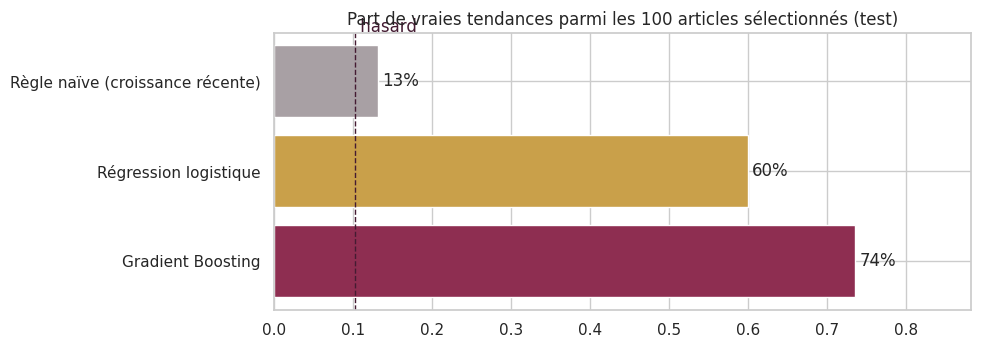

In [ ]:
fig, ax = plt.subplots(figsize=(9, 3.6))
valeurs = resultats_m2["Précision des 100 premiers"]
barres = ax.barh(valeurs.index, valeurs.values, color=[GRIS, OR, PRUNE])
ax.bar_label(barres, labels=[f"{v:.0%}" for v in valeurs], padding=3)
ax.axvline(yte.mean(), color=NUIT, ls="--", lw=1)
ax.text(yte.mean(), -0.6, " hasard", color=NUIT, va="center")
ax.set_title("Part de vraies tendances parmi les 100 articles sélectionnés (test)")
ax.set_xlim(0, max(valeurs.max() * 1.2, 0.1))
ax.invert_yaxis()
plt.show()

> **Interprétation**
>
> Ce graphique résume l'apport du Machine Learning pour la décision : sur 100 articles sélectionnés, on passe de **13 vraies tendances** avec la règle naïve à **74 avec le Gradient Boosting**. La ligne pointillée indique le niveau du hasard.

### 10.4 Quelles variables comptent ?

On mélange une variable au hasard et on mesure la perte d'AUC .
Plus la perte est grande, plus le modèle s'appuie sur cette variable.

> **Pourquoi ce choix ?**
>
> L'importance par permutation fonctionne avec n'importe quel modèle et se lit directement : « que perd-on si le modèle n'a plus accès à cette information ? ». Elle est mesurée sur des données de test, donc elle reflète ce qui aide vraiment à prédire.

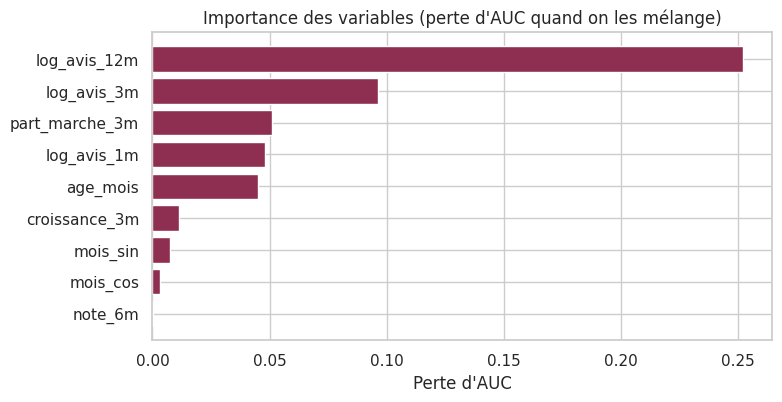

In [ ]:
extrait = d_test.sample(min(30_000, len(d_test)), random_state=SEED)
imp = permutation_importance(gbm, extrait[VARIABLES], extrait["tendance"], scoring="roc_auc",
                             n_repeats=3, random_state=SEED)
importance = pd.Series(imp.importances_mean, index=VARIABLES).sort_values()

fig, ax = plt.subplots(figsize=(8, 4))
ax.barh(importance.index, importance.values, color=PRUNE)
ax.set_title("Importance des variables (perte d'AUC quand on les mélange)")
ax.set_xlabel("Perte d'AUC")
plt.show()

> **Interprétation**
>
> - **Le volume sur 12 mois domine** (perte d'AUC de 0,25), suivi du **volume sur 3 mois**. Un article installé dans la durée, avec une demande de fond, a plus de chances de décoller qu'un article qui a connu un pic récent.
> - **La part de marché, le volume du dernier mois et l'âge** jouent un rôle secondaire.
> - **La croissance récente compte peu**, ce qui confirme l'échec de la règle naïve.
> - **La note n'a aucun effet** sur la tendance : la satisfaction ne prédit pas la demande. Ce résultat rejoint celui du modèle 1 et justifie à nouveau de combiner les deux signaux.

### Conclusion du modèle 2

- Le **Gradient Boosting** est retenu : AUC de 0,80, et 74 % de vraies tendances parmi les 100 premiers articles.
- **Sortie transmise au modèle 3 :** la **probabilité de tendance** de chaque article.

## 11. Modèle 3 : composition de la collection

**Objectif :** choisir **100 articles** qui seront à la fois **demandés** et **appréciés**.

**Score d'un article :**

$$\text{score} = P(\text{tendance}) \times \frac{\text{note attendue} - 1}{4}$$

- P(tendance) vient du **modèle 2** (demande) ;
- la note attendue vient du **modèle 1** (satisfaction) ; elle est recalculée à chaque date avec les seules notes connues à cette date, pour ne jamais utiliser le futur ;
- le facteur (note − 1) / 4 ramène la note entre 0 et 1.

**Contraintes métier :**
- note attendue ≥ **4** : on refuse un article médiocre, même s'il est populaire ;
- au plus **3 articles par marque**, pour diversifier la collection (contrainte active seulement si les métadonnées sont disponibles).

### Pourquoi une sélection gloutonne ?

**Principe :** on classe les articles du meilleur au moins bon score, puis on les prend un par un. On garde un article seulement s'il respecte les contraintes (taille, marque...), et on s'arrête à 100.

**Pourquoi ce choix ?**
- **Simple :** c'est comme remplir un sac en commençant par les objets les plus utiles.
- **Rapide :** le résultat est instantané, même avec 88 000 candidats.

In [ ]:
def note_attendue(t, lam=10.0):
    """Biais article du modèle 1, calculé avec les notes publiées jusqu'au mois t inclus."""
    somme, nb = CUM_SOMME_NOTES[:, t + 1], CUM_NB_NOTES[:, t + 1]
    mu = somme.sum() / nb.sum()
    return mu + (somme - mu * nb) / (nb + lam)

# Métadonnées facultatives : marque et prix
if os.path.exists(CHEMIN_META):
    morceaux = []
    for bloc in pd.read_json(CHEMIN_META, lines=True, chunksize=200_000, dtype=False):
        bloc = bloc[[c for c in ["parent_asin", "store", "price"] if c in bloc.columns]]
        morceaux.append(bloc[bloc["parent_asin"].isin(produits)])
    meta = pd.concat(morceaux).drop_duplicates("parent_asin").set_index("parent_asin")
    meta["price"] = pd.to_numeric(meta.get("price"), errors="coerce")
    meta = meta.reindex(produits)
    print(f"Métadonnées trouvées pour {meta['store'].notna().mean():.0%} des articles suivis")
else:
    meta = pd.DataFrame({"store": np.nan, "price": np.nan}, index=produits)
    print("Pas de fichier de métadonnées : la contrainte de marque est ignorée.")
MARQUE = meta["store"].to_numpy()
PRIX = meta["price"].to_numpy()

def candidats(t):
    d = construire(t)
    d["note_6m"] = d["note_6m"].fillna(note_moy_train)
    d["proba_tendance"] = gbm.predict_proba(d[VARIABLES])[:, 1]
    d["note_attendue"] = note_attendue(t)[d["produit"]]
    d["score"] = d["proba_tendance"] * (d["note_attendue"] - 1) / 4
    d["marque"], d["prix"] = MARQUE[d["produit"]], PRIX[d["produit"]]
    return d

def composer(d, n=TAILLE_COLLECTION, max_marque=MAX_PAR_MARQUE, note_min=NOTE_MIN):
    choix, par_marque = [], {}
    for idx, ligne in d[d["note_attendue"] >= note_min].sort_values("score", ascending=False).iterrows():
        m = ligne["marque"]
        if isinstance(m, str):
            if par_marque.get(m, 0) >= max_marque:
                continue
            par_marque[m] = par_marque.get(m, 0) + 1
        choix.append(idx)
        if len(choix) == n:
            break
    return d.loc[choix]

Pas de fichier de métadonnées : la contrainte de marque est ignorée.


> **Interprétation**
>
> Le fichier de métadonnées (marque, prix) n'est pas disponible : la contrainte « 3 articles maximum par marque » est donc ignorée. Le reste de la méthode fonctionne normalement.

### 11.1 Backtest : la méthode fait-elle mieux que des règles simples ?

On se replace à chaque date de test (de 2022 à 2023). On compose une collection **avec les seules informations disponibles à cette date**, puis on observe ce qui s'est réellement passé dans les 3 mois suivants.

On compare quatre stratégies de 100 articles :
- **Hasard** ;
- **Les plus populaires** : les best-sellers actuels, la règle la plus courante en pratique ;
- **Les mieux notés** : le modèle 1 seul ;
- **Notre score** : modèle 1 × modèle 2, sous contraintes.

> **Pourquoi ce choix ?**
>
> Un backtest sur **plusieurs dates** prouve que le résultat n'est pas un coup de chance lié à une seule saison. Comparer à des stratégies qu'un acheteur pourrait appliquer sans Machine Learning (best-sellers, meilleures notes) mesure la **valeur ajoutée réelle** du projet.

In [ ]:
lignes = []
for t in dates_test:
    d = candidats(t)
    strategies = {
        "Hasard": d.sample(min(TAILLE_COLLECTION, len(d)), random_state=SEED),
        "Les plus populaires": d.nlargest(TAILLE_COLLECTION, "avis_3m"),
        "Les mieux notés": d.nlargest(TAILLE_COLLECTION, "note_attendue"),
        "Notre score": composer(d),
    }
    marche = d["avis_futurs"].sum() / max(d["avis_3m"].sum(), 1)
    for nom, c in strategies.items():
        lignes.append({
            "date": str(vers_mois(debut_num + t)), "stratégie": nom,
            "% de vraies tendances": c["tendance"].mean(),
            "croissance vs marché": np.median((c["avis_futurs"] + 1) / (c["avis_3m"] + 1)) / marche,
            "note réelle future": c["note_future"].mean(),
        })
backtest = pd.DataFrame(lignes)
synthese_m3 = backtest.groupby("stratégie", sort=False)[["% de vraies tendances", "croissance vs marché", "note réelle future"]].mean()
synthese_m3

,% de vraies tendances,croissance vs marché,note réelle future
stratégie,,,
Hasard,0.096,1.310,4.193
Les plus populaires,0.038,0.755,4.279
Les mieux notés,0.098,1.139,4.806
Notre score,0.704,3.165,4.473


> **Interprétation**
>
> | Stratégie | % de vraies tendances | Croissance vs marché | Note réelle |
> |---|---|---|---|
> | Hasard | 10 % | x1,31 | 4,19 |
> | Les plus populaires | 4 % | x0,76 | 4,28 |
> | Les mieux notés | 10 % | x1,14 | **4,81** |
> | **Notre score** | **70 %** | **x3,17** | 4,47 |
>
> - **Notre collection contient 7 fois plus de vraies tendances que le hasard**, et ses articles ont progressé **3 fois plus vite que le marché**.
> - **Les best-sellers régressent** (x0,76) : ce qui se vend le plus aujourd'hui est souvent en fin de cycle de vie. Suivre les ventes passées est la **pire** stratégie pour anticiper.
> - **Les mieux notés** satisfont le plus (4,81), mais leur demande n'augmente pas : la satisfaction seule ne crée pas la tendance.
> - **Notre score réalise le meilleur compromis** : une forte demande future et une note réelle élevée (4,47, bien au-dessus du hasard).

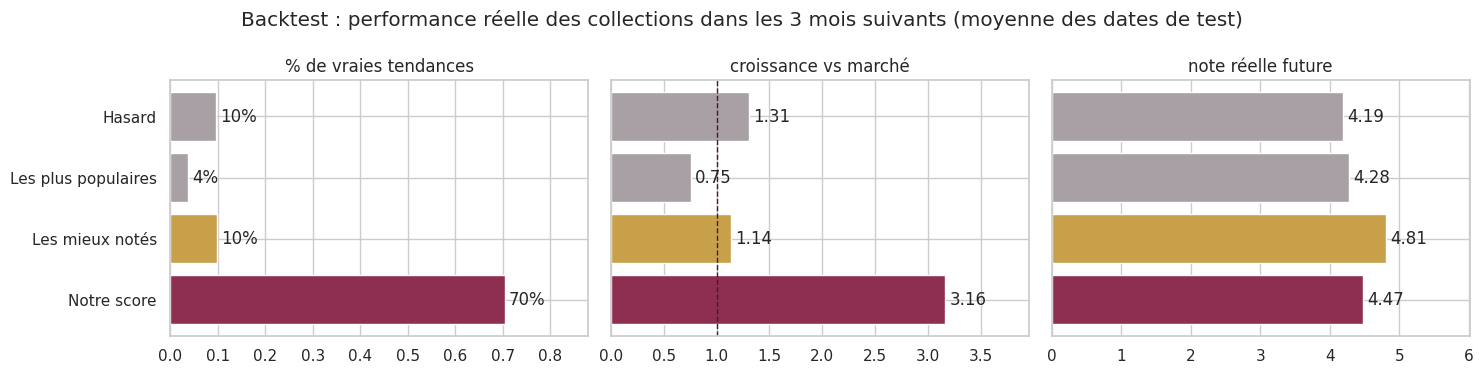

In [ ]:
couleurs = [GRIS, GRIS, OR, PRUNE]
fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))
for ax, col in zip(axes, synthese_m3.columns):
    barres = ax.barh(synthese_m3.index, synthese_m3[col], color=couleurs)
    fmt = "{:.0%}" if col.startswith("%") else "{:.2f}"
    ax.bar_label(barres, labels=[fmt.format(v) for v in synthese_m3[col]], padding=3)
    ax.set_title(col)
    ax.invert_yaxis()
    ax.set_xlim(0, synthese_m3[col].max() * 1.25)
    if col == "croissance vs marché":
        ax.axvline(1, color=NUIT, ls="--", lw=1)
for ax in axes[1:]:
    ax.set_yticklabels([])
fig.suptitle("Backtest : performance réelle des collections dans les 3 mois suivants (moyenne des dates de test)")
plt.tight_layout()
plt.show()

> **Interprétation**
>
> Les trois graphiques résument le résultat : notre score domine nettement sur la **demande** (vraies tendances et croissance) et reste dans le haut du classement sur la **satisfaction**. C'est exactement l'objectif fixé.

### 11.2 Recommandation pour la prochaine saison

On se place au dernier mois complet des données (août 2023) et on compose la collection de **septembre à novembre 2023**.

In [ ]:
t_final = NT - 1
d_final = candidats(t_final)
collection = composer(d_final)
mois_prevus = [str(vers_mois(debut_num + t_final + h)) for h in range(1, HORIZON + 1)]
print(f"Collection pour {mois_prevus[0]} -> {mois_prevus[-1]} : {len(collection)} articles parmi {len(d_final):,} candidats")
if collection["marque"].notna().any():
    print(f"Marques différentes : {collection['marque'].nunique()} | prix médian : {collection['prix'].median():.2f} $")

collection_affichee = collection.assign(article=np.asarray(produits)[collection["produit"]])[
    ["article", "marque", "prix", "proba_tendance", "note_attendue", "score"]].reset_index(drop=True)
collection_affichee.index += 1
collection_affichee.to_csv("collection_recommandee.csv", index_label="rang")
collection_affichee.head(20)

Collection pour 2023-09 -> 2023-11 : 100 articles parmi 88,307 candidats


,article,marque,prix,proba_tendance,note_attendue,score
1,B0811PPV9P,NaN,NaN,0.905,4.773,0.854
2,B078H5DXX8,NaN,NaN,0.895,4.794,0.849
3,B07X9V6HZX,NaN,NaN,0.925,4.661,0.846
4,B079P34V7X,NaN,NaN,0.923,4.663,0.846
5,B09FZ57B1X,NaN,NaN,0.893,4.767,0.841
6,B07H5G8D7R,NaN,NaN,0.858,4.884,0.833
7,B0BMLRLR7N,NaN,NaN,0.888,4.755,0.833
8,B09D93KPSG,NaN,NaN,0.866,4.847,0.833
9,B07VSF19TF,NaN,NaN,0.907,4.663,0.831
10,B0BPBVBM7X,NaN,NaN,0.873,4.781,0.825


> **Interprétation**
>
> - **100 articles** sont retenus parmi **88 307 candidats**.
> - Les articles en tête combinent une **probabilité de tendance élevée** (85 à 93 %) et une **note attendue élevée** (4,6 à 4,9).
> - La liste complète est exportée dans `collection_recommandee.csv`.
>
> **Limite :** cette période se situe après la fin des données (mi-septembre 2023). On ne peut donc pas encore la vérifier : c'est l'objet de la section suivante.

### 11.3 Vérification : prédiction contre réalité

Pour vérifier concrètement les prédictions, on **rejoue** la procédure sur la période réelle la plus récente dont on connaît la suite.

Trois choix méthodologiques :
1. **La date de vérification** est choisie là où les données sont complètes : on écarte automatiquement les derniers mois, où le taux de tendances s'effondre à cause de la collecte (voir section 8.3). Ce critère porte sur la **qualité des données**, jamais sur les résultats du modèle.
2. **Le modèle 2 est réentraîné** avec tout l'historique connu à cette date (*walk-forward*), comme le ferait une entreprise avant chaque saison.
3. **Nouvelle variante de score :** on classe par probabilité de tendance, et la note sert seulement de filtre (≥ 4). On la compare à la méthode précédente.

Taux de tendances à l'entraînement : 10.7%
Date de vérification retenue : fin 2023-02 (prédiction pour 2023-03 -> 2023-05)
Modèle réentraîné sur 1,500,000 lignes (28 dates jusqu'à fin 2022-09)

AUC sur tous les candidats : ancien modèle 0.816 | modèle réentraîné 0.814


,vraies tendances,% de vraies tendances,croissance médiane vs marché,note réelle moyenne
Hasard,10,10%,x1.10,4.29
Les plus populaires,1,1%,x0.66,4.31
Ancienne méthode,78,78%,x2.22,4.44
Nouvelle méthode,81,81%,x2.63,4.32


81 articles sur 100 ont réellement été en tendance sur 2023-03 -> 2023-05, soit 81% contre 9% pour un choix au hasard.


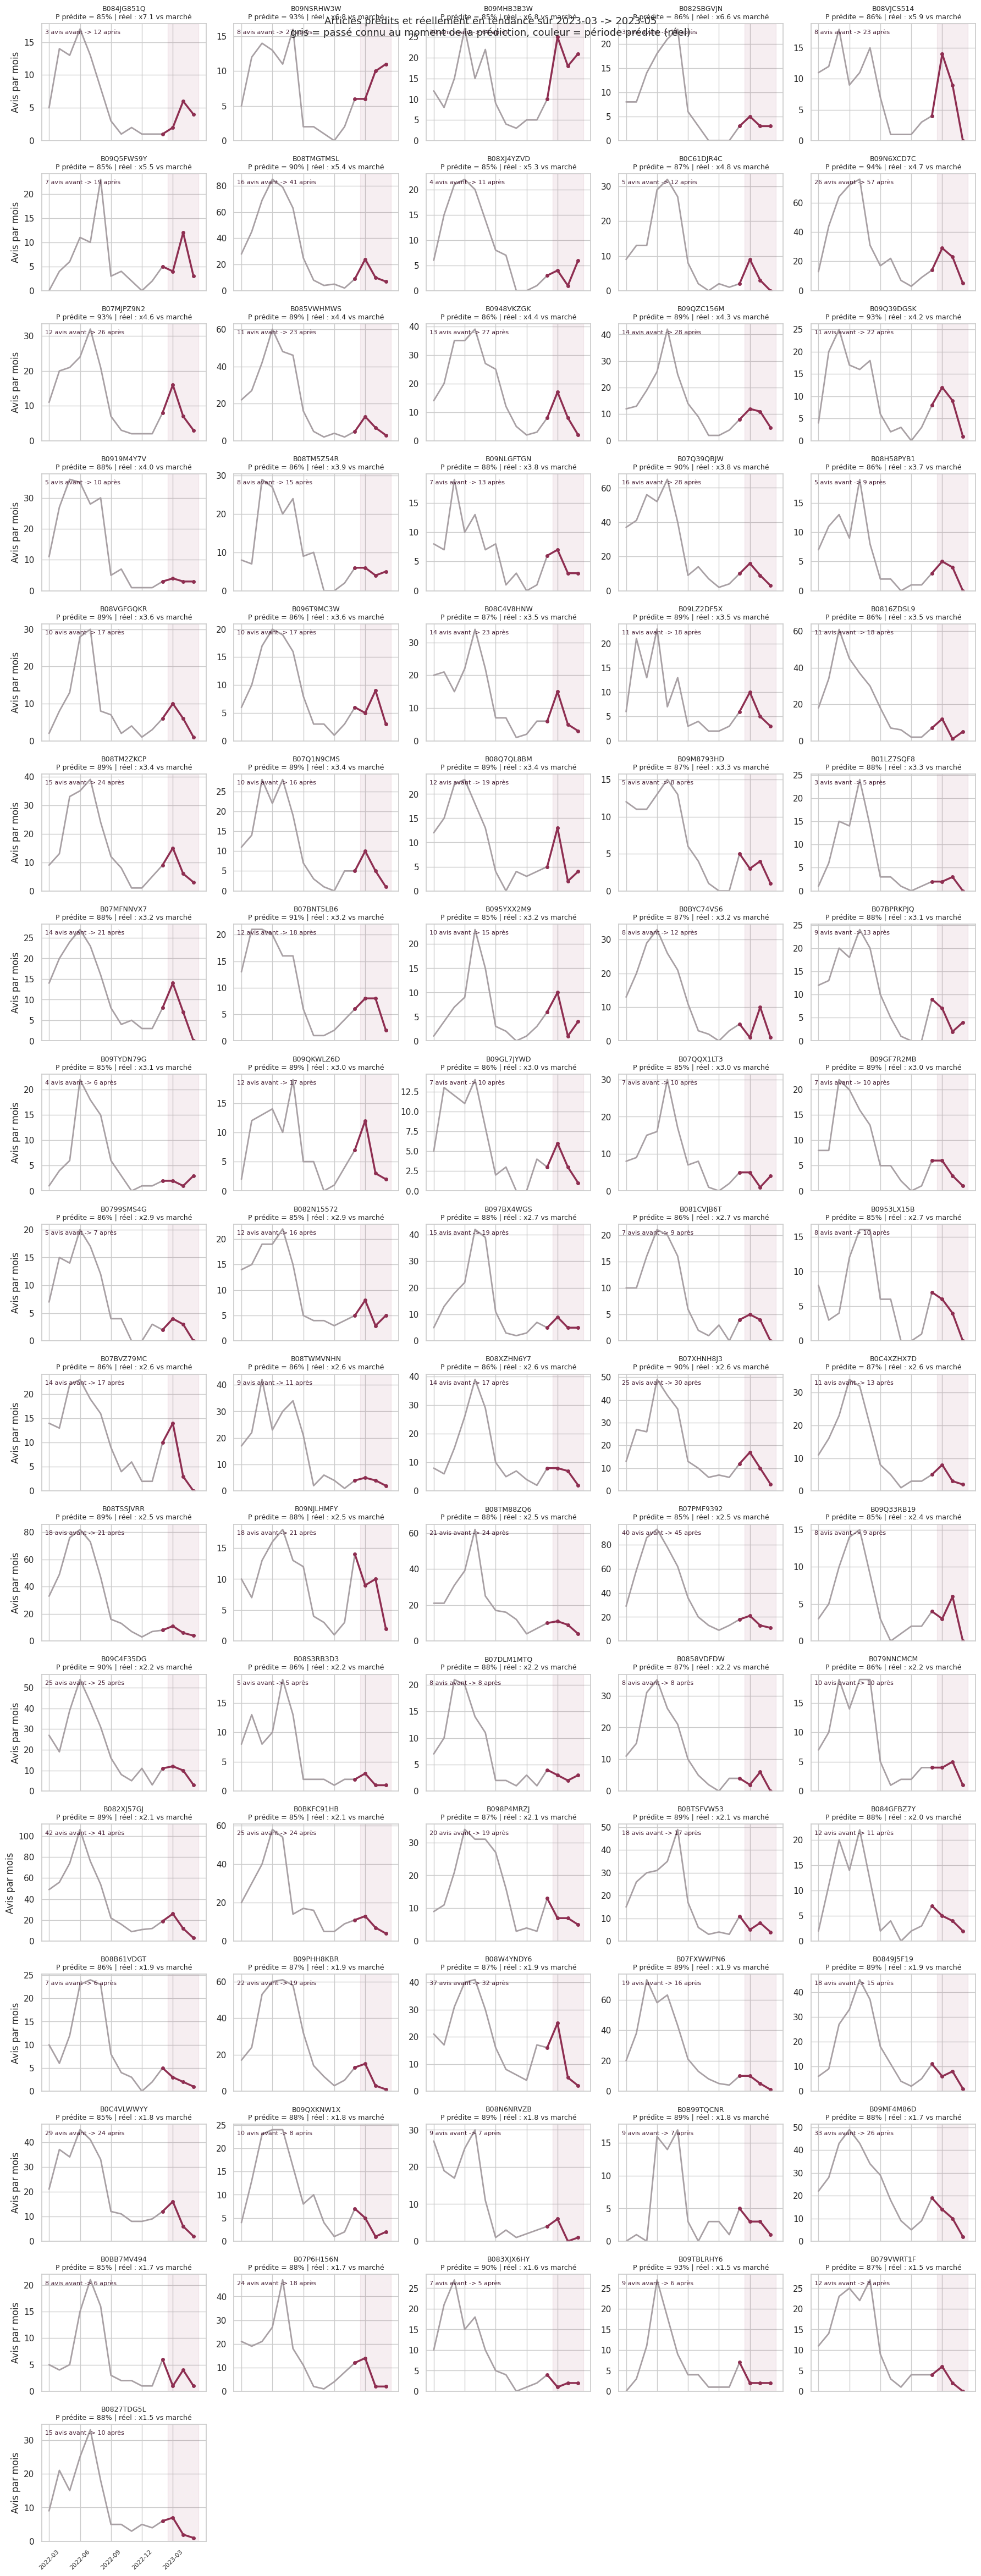

,article,P(tendance) prédite,avis 3 mois avant,avis 3 mois après,croissance vs marché,note attendue,note réelle,lien Amazon
1,B084JG851Q,85%,3,12,x7.15,4.33,4.08,voir
2,B09NSRHW3W,93%,8,27,x6.84,4.50,4.37,voir
3,B09MHB3B3W,85%,20,64,x6.80,4.36,4.42,voir
4,B082SBGVJN,86%,3,11,x6.60,4.11,4.22,voir
5,B08VJCS514,86%,8,23,x5.86,4.37,4.68,voir
6,B09Q5FWS9Y,85%,7,19,x5.50,4.29,4.16,voir
7,B08TMGTMSL,90%,16,41,x5.43,4.11,4.00,voir
8,B08XJ4YZVD,85%,4,11,x5.28,4.32,3.91,voir
9,B0C61DJR4C,87%,5,12,x4.76,4.51,4.58,voir
10,B09N6XCD7C,94%,26,57,x4.72,4.36,4.33,voir


In [ ]:
# ============ 1. Date de vérification où les données sont complètes ============
taux_train = d_train["tendance"].mean()
t_verif = None
for t in range(NT - 1 - HORIZON, t_coupure, -1):
    taux = construire(t)["tendance"].mean()
    if taux >= 0.5 * taux_train:             # données jugées complètes
        t_verif = t
        break
print(f"Taux de tendances à l'entraînement : {taux_train:.1%}")
print(f"Date de vérification retenue : fin {vers_mois(debut_num + t_verif)} "
      f"(prédiction pour {vers_mois(debut_num + t_verif + 1)} -> {vers_mois(debut_num + t_verif + HORIZON)})")

# ============ 2. Réentraînement avec tout ce qui est connu à cette date ============
dates_wf = list(range(11, t_verif - HORIZON + 1, 3))         # cibles entièrement connues à t_verif
d_wf = pd.concat([construire(t) for t in dates_wf], ignore_index=True)
if len(d_wf) > 1_500_000:
    d_wf = d_wf.sample(1_500_000, random_state=SEED)
d_wf["note_6m"] = d_wf["note_6m"].fillna(note_moy_train)
gbm_wf = HistGradientBoostingClassifier(max_iter=300, learning_rate=0.05, max_leaf_nodes=31,
                                        early_stopping=True, random_state=SEED)
gbm_wf.fit(d_wf[VARIABLES], d_wf["tendance"])
print(f"Modèle réentraîné sur {len(d_wf):,} lignes ({len(dates_wf)} dates jusqu'à fin {vers_mois(debut_num + dates_wf[-1])})")

# ============ 3. Candidats et stratégies ============
d_verif = construire(t_verif)
d_verif["note_6m"] = d_verif["note_6m"].fillna(note_moy_train)
d_verif["proba_ancien"] = gbm.predict_proba(d_verif[VARIABLES])[:, 1]
d_verif["proba_tendance"] = gbm_wf.predict_proba(d_verif[VARIABLES])[:, 1]
d_verif["note_attendue"] = note_attendue(t_verif)[d_verif["produit"]]
d_verif["marque"], d_verif["prix"] = MARQUE[d_verif["produit"]], PRIX[d_verif["produit"]]
marche_verif = d_verif["avis_futurs"].sum() / max(d_verif["avis_3m"].sum(), 1)
d_verif["croissance_reelle"] = ((d_verif["avis_futurs"] + 1) / (d_verif["avis_3m"] + 1)) / marche_verif

strategies = {
    "Hasard": d_verif.sample(TAILLE_COLLECTION, random_state=SEED),
    "Les plus populaires": d_verif.nlargest(TAILLE_COLLECTION, "avis_3m"),
    "Ancienne méthode": composer(d_verif.assign(score=d_verif["proba_ancien"] * (d_verif["note_attendue"] - 1) / 4)),
    "Nouvelle méthode": composer(d_verif.assign(score=d_verif["proba_tendance"])),   # note >= NOTE_MIN reste un filtre
}
comparaison = pd.DataFrame({nom: {
    "vraies tendances": int(c["tendance"].sum()),
    "% de vraies tendances": c["tendance"].mean(),
    "croissance médiane vs marché": c["croissance_reelle"].median(),
    "note réelle moyenne": c["note_future"].mean(),
} for nom, c in strategies.items()}).T
print(f"\nAUC sur tous les candidats : ancien modèle {roc_auc_score(d_verif['tendance'], d_verif['proba_ancien']):.3f} "
      f"| modèle réentraîné {roc_auc_score(d_verif['tendance'], d_verif['proba_tendance']):.3f}")
display(comparaison.style.format({"vraies tendances": "{:.0f}", "% de vraies tendances": "{:.0%}",
                                  "croissance médiane vs marché": "x{:.2f}", "note réelle moyenne": "{:.2f}"}))

coll_verif = strategies["Nouvelle méthode"]
periode_verif = [str(vers_mois(debut_num + t_verif + h)) for h in range(1, HORIZON + 1)]

# ============ 4. Articles prédits ET réellement en tendance ============
gagnants = coll_verif[coll_verif["tendance"] == 1].sort_values("croissance_reelle", ascending=False)
periode_txt = f"{periode_verif[0]} -> {periode_verif[-1]}"
print(f"{len(gagnants)} articles sur {len(coll_verif)} ont réellement été en tendance sur {periode_txt}, "
      f"soit {len(gagnants) / len(coll_verif):.0%} contre {d_verif['tendance'].mean():.0%} pour un choix au hasard.")

if len(gagnants) > 0:
    mois_axe = [vers_mois(debut_num + t) for t in range(t_verif - 11, t_verif + HORIZON + 1)]
    x = np.arange(len(mois_axe))
    coupe = 11
    n_lig = int(np.ceil(len(gagnants) / 5))
    fig, axes = plt.subplots(n_lig, 5, figsize=(18, 2.8 * n_lig), sharex=True, squeeze=False)
    for ax, (_, art) in zip(axes.ravel(), gagnants.iterrows()):
        p = int(art["produit"])
        serie = np.diff(CUM_AVIS[p, t_verif - 11: t_verif + HORIZON + 2])
        ax.axvspan(coupe + 0.5, x[-1] + 0.5, color=PRUNE, alpha=0.08)
        ax.plot(x[: coupe + 1], serie[: coupe + 1], color=GRIS, lw=2)
        ax.plot(x[coupe:], serie[coupe:], color=PRUNE, lw=2.5, marker="o", ms=4)
        ax.set_title(f"{produits[p]}\nP prédite = {art['proba_tendance']:.0%} | réel : x{art['croissance_reelle']:.1f} vs marché",
                     fontsize=9)
        ax.text(0.02, 0.95, f"{art['avis_3m']:.0f} avis avant -> {art['avis_futurs']:.0f} après",
                transform=ax.transAxes, fontsize=8, va="top", color=NUIT)
        ax.set_ylim(bottom=0)
    for ax in axes.ravel()[len(gagnants):]:
        ax.axis("off")
    for ax in axes[-1]:
        ax.set_xticks(x[::3])
        ax.set_xticklabels([str(m) for m in mois_axe[::3]], rotation=45, fontsize=8)
    for ax in axes[:, 0]:
        ax.set_ylabel("Avis par mois")
    fig.suptitle(f"Articles prédits et réellement en tendance sur {periode_txt}\n"
                 "gris = passé connu au moment de la prédiction, couleur = période prédite (réel)", fontsize=13)
    plt.tight_layout()
    plt.show()

    tableau_gagnants = gagnants.assign(
        article=np.asarray(produits)[gagnants["produit"].astype(int)],
        lien=lambda d: "https://www.amazon.com/dp/" + d["article"],
    )[["article", "proba_tendance", "avis_3m", "avis_futurs", "croissance_reelle", "note_attendue", "note_future", "lien"]]
    tableau_gagnants.columns = ["article", "P(tendance) prédite", "avis 3 mois avant", "avis 3 mois après",
                                "croissance vs marché", "note attendue", "note réelle", "lien Amazon"]
    tableau_gagnants = tableau_gagnants.reset_index(drop=True)
    tableau_gagnants.index += 1
    tableau_gagnants.to_csv("articles_tendance_confirmes.csv", index_label="rang")
    display(tableau_gagnants.style.format({
        "P(tendance) prédite": "{:.0%}", "avis 3 mois avant": "{:,.0f}", "avis 3 mois après": "{:,.0f}",
        "croissance vs marché": "x{:.2f}", "note attendue": "{:.2f}", "note réelle": "{:.2f}",
        "lien Amazon": lambda u: f'<a href="{u}" target="_blank">voir</a>',
    }))

> **Interprétation**
>
> **Contexte :** prédiction faite fin février 2023, pour mars à mai 2023. Le taux de tendances est normal à cette date (environ 10 %), donc les données sont complètes.
>
> | Stratégie | Vraies tendances sur 100 | Croissance médiane vs marché | Note réelle |
> |---|---|---|---|
> | Hasard | 10 | x1,10 | 4,29 |
> | Les plus populaires | 1 | x0,66 | 4,31 |
> | Ancienne méthode (proba × note) | 78 | x2,22 | **4,44** |
> | **Nouvelle méthode (proba, note ≥ 4)** | **81** | **x2,63** | 4,32 |
>
> - **81 articles sur 100 ont réellement été en tendance**, contre 9 à 10 pour un choix au hasard : la collection est **8 fois plus performante** que le hasard.
> - **Le réentraînement change très peu l'AUC** (0,816 contre 0,814) : le modèle entraîné avant 2022 reste valable en 2023, ce qui montre sa **robustesse dans le temps**.
> - **Arbitrage métier :** la nouvelle méthode capte un peu plus de demande (81 % contre 78 %), au prix d'une note un peu plus faible (4,32 contre 4,44). Le choix entre les deux dépend de la priorité de l'enseigne : volume ou satisfaction.
> - **Les courbes** montrent, article par article, le volume d'avis avant la prédiction (en gris) puis la hausse réelle pendant la période prévue (en couleur). Le tableau donne un lien vers la fiche Amazon de chaque article.
>
> **Point de vigilance :** la croissance est mesurée **par rapport au marché**. Entre l'hiver et le printemps, le volume total d'avis a baissé d'environ moitié (effet post-fêtes). Un article stable en valeur absolue compte donc comme « en tendance ». Environ 55 des 81 articles ont aussi progressé **en valeur absolue**.

---
# Partie IV : Synthèse

## 12. Conclusion

### Réponse à la problématique

> **Oui** : à partir des seuls avis clients, on peut identifier à l'avance les articles qui vont gagner en popularité. Dans le backtest, la collection proposée contient **7 à 8 fois plus d'articles en tendance qu'un choix au hasard**, tout en restant mieux notée que le hasard.

### Résultats clés

| Objectif | Résultat |
|---|---|
| O1 : données | 24,3 M d'avis nettoyés (doublons, notes invalides, lignes incomplètes) ; constats clés : notes très positives, matrice creuse à 99,999 %, saisonnalité de fin d'année, fin de données incomplète |
| O2 : préférences | modèle à biais : MAE réduite de 10 % par rapport à la moyenne, AUC de 0,69 ; la SVD n'apporte rien de plus |
| O3 : tendances | Gradient Boosting : AUC de 0,80, **74 %** de vraies tendances parmi les 100 premiers (contre 10 % au hasard) |
| O4 : collection | backtest : **70 %** de vraies tendances, croissance **x3,2** par rapport au marché, note réelle de 4,47 |
| O5 : vérification | mars-mai 2023 : **81 articles sur 100** réellement en tendance |


### Limites

- Le **nombre d'avis** est un indicateur des ventes, pas les ventes elles-mêmes.
- Les **métadonnées** (marque, prix, catégorie) n'ont pas été utilisées : la contrainte de diversité n'a pas pu s'appliquer.
- Le modèle 1 a été entraîné sur un **échantillon** de 300 000 clients, par contrainte de mémoire.
- Les articles de **moins de 6 mois** ne sont pas candidats, faute d'historique.
- La **fin des données** (2023) est incomplète, ce qui limite la vérification de la dernière collection.

### Perspectives

- Intégrer les **métadonnées** : catégorie et prix comme variables, contraintes de budget et de diversité.
- Traiter les **nouveaux articles** à partir de leur description (texte, images).
- **Personnaliser** la collection par segment de clients à partir des profils du modèle 1.
- Remplacer la sélection gloutonne par une **optimisation linéaire en nombres entiers** pour gérer des contraintes plus riches.
- Vérifier la collection septembre-novembre 2023 dès qu'une version plus récente des données sera disponible.

## 13. Références

**Données**
- Hou, Y., Li, J., He, Z., Yan, A., Chen, X., & McAuley, J. (2024). *Bridging Language and Items for Retrieval and Recommendation*. arXiv:2403.03952. Jeu de données Amazon Reviews 2023 : https://amazon-reviews-2023.github.io/

**Modèle 1 : systèmes de recommandation**
- Koren, Y., Bell, R., & Volinsky, C. (2009). Matrix Factorization Techniques for Recommender Systems. *Computer*, 42(8), 30-37.
- Koren, Y. (2010). Factor in the Neighbors: Scalable and Accurate Collaborative Filtering. *ACM Transactions on Knowledge Discovery from Data*, 4(1).
- Cremonesi, P., Koren, Y., & Turrin, R. (2010). Performance of Recommender Algorithms on Top-N Recommendation Tasks. *Proceedings of the 4th ACM Conference on Recommender Systems (RecSys)*, 39-46.
- Krichene, W., & Rendle, S. (2020). On Sampled Metrics for Item Recommendation. *Proceedings of the 26th ACM SIGKDD Conference (KDD)*, 1748-1757.

**Modèle 2 : apprentissage supervisé**
- Friedman, J. H. (2001). Greedy Function Approximation: A Gradient Boosting Machine. *Annals of Statistics*, 29(5), 1189-1232.
- Ke, G., et al. (2017). LightGBM: A Highly Efficient Gradient Boosting Decision Tree. *Advances in Neural Information Processing Systems (NeurIPS)*, 30.
- Breiman, L. (2001). Random Forests. *Machine Learning*, 45(1), 5-32 (importance par permutation).
- Hastie, T., Tibshirani, R., & Friedman, J. (2009). *The Elements of Statistical Learning* (2e éd.). Springer.
- Hyndman, R. J., & Athanasopoulos, G. (2021). *Forecasting: Principles and Practice* (3e éd.). OTexts (validation temporelle).

**Modèle 3 : optimisation**
- Dantzig, G. B. (1957). Discrete-Variable Extremum Problems. *Operations Research*, 5(2), 266-288.

**Outils**
- Pedregosa, F., et al. (2011). Scikit-learn: Machine Learning in Python. *Journal of Machine Learning Research*, 12, 2825-2830.
- Harris, C. R., et al. (2020). Array Programming with NumPy. *Nature*, 585, 357-362.
- McKinney, W. (2010). Data Structures for Statistical Computing in Python. *Proceedings of the 9th Python in Science Conference*, 56-61.
- Virtanen, P., et al. (2020). SciPy 1.0: Fundamental Algorithms for Scientific Computing in Python. *Nature Methods*, 17, 261-272.